# Himawari L2 AOD — EDA & Availability Validation

**Source archive:** `/home/slow_data/Air_Quality/Himawari/L2_AOD/`  
**Layout:** `yyyymm/dd/hh/aod_vietnam_NC_H0{8,9}_{YYYYMMDD}_{HHMM}_L2ARP031_FLDK.*.tif`
(6 sub-files per hour at a 10-minute cadence: `_0000`, `_0010`, …, `_0050`).

**Two goals:**
1. Inventory file completeness (expected 6 files/hour × 24 h/day).
2. Validate the published claim:
   > *Valid Himawari L2 retrievals are available for only ≈10.3 % of all hourly observation slots on an annual basis, ≈6.9 % in July, ≈16.7 % in April.*

GeoTIFF band layout (6 bands):
`1=AOT(500nm)`, `2=Uncertainty`, `3=AE`, `4=QA_flag` (bitmask), `5=SSA`, `6=RF` (fine-mode fraction).

In [1]:
import os, re, glob, time, json
from pathlib import Path
from datetime import datetime, timedelta
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio

sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

L2_DIR = Path('/home/slow_data/Air_Quality/Himawari/L2_AOD')
EXPECTED_FILES_PER_HOUR = 6     # 10-min cadence: 00,10,20,30,40,50
EXPECTED_HOURS_PER_DAY  = 24

## 1. Inventory — what hourly slots exist?

Walk `yyyymm/dd/hh/` and count `.tif` files per hourly slot. Each row of the inventory DataFrame is one hourly slot.

In [2]:
rows = []
for ym_dir in sorted(L2_DIR.glob('[0-9][0-9][0-9][0-9][0-9][0-9]')):
    ym = ym_dir.name
    for dd_dir in sorted(ym_dir.glob('[0-9][0-9]')):
        day = dd_dir.name
        hour_dirs = list(dd_dir.glob('[0-9][0-9]'))
        present_hours = {d.name for d in hour_dirs}
        # Account for missing hour dirs as 0-file slots
        for hh_str in [f'{h:02d}' for h in range(EXPECTED_HOURS_PER_DAY)]:
            if hh_str in present_hours:
                n_files = len(list((dd_dir / hh_str).glob('*.tif')))
            else:
                n_files = 0
            rows.append({
                'year_month': ym,
                'day': day,
                'hour': hh_str,
                'slot_utc': f'{ym}{day}{hh_str}',
                'n_files': n_files,
                'expected': EXPECTED_FILES_PER_HOUR,
                'status': ('complete' if n_files == EXPECTED_FILES_PER_HOUR
                           else ('empty' if n_files == 0 else 'incomplete')),
                'missing': max(0, EXPECTED_FILES_PER_HOUR - n_files),
            })
df = pd.DataFrame(rows)
df['datetime_utc'] = pd.to_datetime(df['slot_utc'], format='%Y%m%d%H')
print(f'Total hourly slots scanned: {len(df):,}')
df.head()

Total hourly slots scanned: 32,376


,year_month,day,hour,slot_utc,n_files,expected,status,missing,datetime_utc
0,202001,01,00,2020010100,0,6,empty,6,2020-01-01 00:00:00
1,202001,01,01,2020010101,0,6,empty,6,2020-01-01 01:00:00
2,202001,01,02,2020010102,0,6,empty,6,2020-01-01 02:00:00
3,202001,01,03,2020010103,0,6,empty,6,2020-01-01 03:00:00
4,202001,01,04,2020010104,0,6,empty,6,2020-01-01 04:00:00


In [3]:
print('=== OVERALL FILE-LEVEL STATISTICS ===')
print(f'Hourly slots scanned        : {len(df):,}')
print(f'Total files found           : {df["n_files"].sum():,}')
print(f'Expected total files        : {len(df) * EXPECTED_FILES_PER_HOUR:,}')
print(f'Missing files               : {df["missing"].sum():,}')
print()
print(f'Complete slots (6 files)    : {(df["status"]=="complete").sum():,}'
      f'  ({100*(df["status"]=="complete").mean():.2f}%)')
print(f'Partial slots (1–5 files)   : {(df["status"]=="incomplete").sum():,}'
      f'  ({100*(df["status"]=="incomplete").mean():.2f}%)')
print(f'Empty slots (0 files)       : {(df["status"]=="empty").sum():,}'
      f'  ({100*(df["status"]=="empty").mean():.2f}%)')

=== OVERALL FILE-LEVEL STATISTICS ===
Hourly slots scanned        : 32,376
Total files found           : 189,983
Expected total files        : 194,256
Missing files               : 4,273

Complete slots (6 files)    : 29,017  (89.63%)
Partial slots (1–5 files)   : 3,213  (9.92%)
Empty slots (0 files)       : 146  (0.45%)


In [4]:
print('=== FILES PER HOURLY SLOT — DISTRIBUTION ===')
print(df['n_files'].value_counts().sort_index())
print('\nPercentage:')
print((df['n_files'].value_counts(normalize=True).sort_index() * 100).round(3))

=== FILES PER HOURLY SLOT — DISTRIBUTION ===
n_files
0      146
1       17
2       17
3       17
4       31
5     3131
6    29017
Name: count, dtype: int64

Percentage:
n_files
0     0.451
1     0.053
2     0.053
3     0.053
4     0.096
5     9.671
6    89.625
Name: proportion, dtype: float64


In [5]:
monthly_stats = df.groupby('year_month').agg(
    n_slots=('n_files', 'count'),
    n_files=('n_files', 'sum'),
    avg_files_per_slot=('n_files', 'mean'),
    missing_files=('missing', 'sum'),
    complete_slots=('status', lambda s: (s=='complete').sum()),
    empty_slots=('status', lambda s: (s=='empty').sum()),
).round(3)
monthly_stats['completeness_pct'] = (
    100 * monthly_stats['complete_slots'] / monthly_stats['n_slots']
).round(2)
print('=== MONTHLY FILE-COMPLETENESS STATISTICS ===')
print(monthly_stats)

=== MONTHLY FILE-COMPLETENESS STATISTICS ===
            n_slots  n_files  avg_files_per_slot  missing_files  \
year_month                                                        
202001           24        0               0.000            144   
202209           96      563               5.865             13   
202210          744     4373               5.878             91   
202211          720     4237               5.885             83   
202212          744     4374               5.879             90   
202301          744     4395               5.907             69   
202302          672     3968               5.905             64   
202303          744     4387               5.897             77   
202304          720     4252               5.906             68   
202305          744     4394               5.906             70   
202306          720     4251               5.904             69   
202307          744     4392               5.903             72   
202308          7

In [6]:
incomplete_df = df[df['status'] != 'complete'].copy()
print(f'\n=== NON-COMPLETE SLOTS ({len(incomplete_df):,} total) ===')
print(incomplete_df[['slot_utc','n_files','status','missing']].head(30))


=== NON-COMPLETE SLOTS (3,359 total) ===
      slot_utc  n_files      status  missing
0   2020010100        0       empty        6
1   2020010101        0       empty        6
2   2020010102        0       empty        6
3   2020010103        0       empty        6
4   2020010104        0       empty        6
5   2020010105        0       empty        6
6   2020010106        0       empty        6
7   2020010107        0       empty        6
8   2020010108        0       empty        6
9   2020010109        0       empty        6
10  2020010110        0       empty        6
11  2020010111        0       empty        6
12  2020010112        0       empty        6
13  2020010113        0       empty        6
14  2020010114        0       empty        6
15  2020010115        0       empty        6
16  2020010116        0       empty        6
17  2020010117        0       empty        6
18  2020010118        0       empty        6
19  2020010119        0       empty        6
20  202001012

/tmp/ipykernel_2892248/2732125277.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly_complete = df.groupby('year_month').apply(lambda x: 100*(x['status']=='complete').mean())


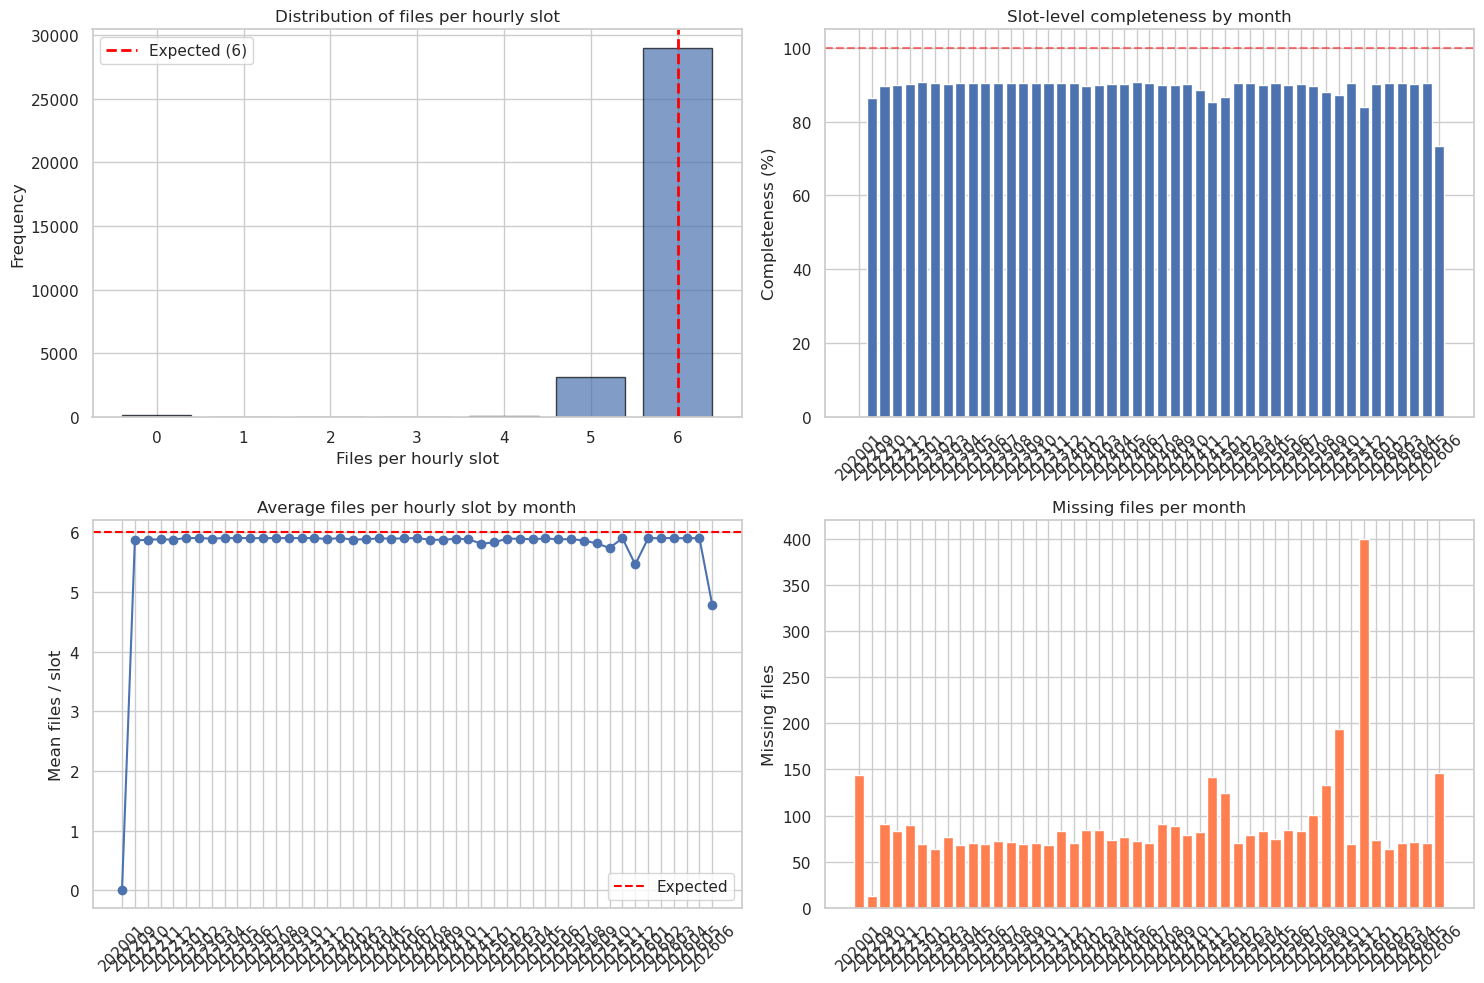

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0,0].hist(df['n_files'], bins=range(0, 8), edgecolor='black', alpha=0.7, align='left', rwidth=0.8)
axes[0,0].set_xlabel('Files per hourly slot')
axes[0,0].set_ylabel('Frequency')
axes[0,0].set_title('Distribution of files per hourly slot')
axes[0,0].axvline(EXPECTED_FILES_PER_HOUR, color='red', ls='--', lw=2, label=f'Expected ({EXPECTED_FILES_PER_HOUR})')
axes[0,0].legend()

monthly_complete = df.groupby('year_month').apply(lambda x: 100*(x['status']=='complete').mean())
axes[0,1].bar(range(len(monthly_complete)), monthly_complete.values)
axes[0,1].set_xticks(range(len(monthly_complete)))
axes[0,1].set_xticklabels(monthly_complete.index, rotation=45)
axes[0,1].set_ylabel('Completeness (%)')
axes[0,1].set_title('Slot-level completeness by month')
axes[0,1].axhline(100, color='red', ls='--', alpha=0.5)

monthly_avg = df.groupby('year_month')['n_files'].mean()
axes[1,0].plot(range(len(monthly_avg)), monthly_avg.values, marker='o')
axes[1,0].set_xticks(range(len(monthly_avg)))
axes[1,0].set_xticklabels(monthly_avg.index, rotation=45)
axes[1,0].set_ylabel('Mean files / slot')
axes[1,0].set_title('Average files per hourly slot by month')
axes[1,0].axhline(EXPECTED_FILES_PER_HOUR, color='red', ls='--', label='Expected')
axes[1,0].legend()

monthly_missing = df.groupby('year_month')['missing'].sum()
axes[1,1].bar(range(len(monthly_missing)), monthly_missing.values, color='coral')
axes[1,1].set_xticks(range(len(monthly_missing)))
axes[1,1].set_xticklabels(monthly_missing.index, rotation=45)
axes[1,1].set_ylabel('Missing files')
axes[1,1].set_title('Missing files per month')

plt.tight_layout()
plt.show()

## 2. Validating the 10.3 % / 6.9 % / 16.7 % claim

**Definition used here.** A *(pixel, hour) cell* is the atomic observation unit. The denominator is
`N_hourly_slots × N_pixels_in_TIF_subdomain` over a year. The numerator counts cells where **at least one**
of the (≤6) sub-hourly L2 retrievals passes QA. Aggregating with `OR` across sub-files is the correct
“hourly-slot is observed” semantic — anything stricter (e.g. requiring all 6 valid) would understate the
geostationary cadence advantage.

**QA rule (JAXA strict).** Reproduces `_qa_passes` from `AOD_map/stage_a/himawari.py`:
all of bits 0, 2, 3, 8, 10, 11, 12, 13 cleared and bits 4–5 == 00 (highest AOT confidence).

**Year selected for validation.** Calendar year **2024** — the only complete year in the archive that
spans Jan–Dec and matches the “annual basis” framing in the claim.

In [8]:
# Reproduce JAXA strict-QA bitmask from AOD_map/stage_a/himawari.py::_qa_passes
def qa_passes(qa):
    q = qa.astype(np.int32)
    return (
        (((q >> 0)  & 1)    == 0)
        & (((q >> 2)  & 1)    == 0)
        & (((q >> 3)  & 1)    == 0)
        & (((q >> 4)  & 0b11) == 0)   # bits 4-5: AOT confidence = 00
        & (((q >> 8)  & 1)    == 0)
        & (((q >> 10) & 1)    == 0)   # Solz/Satz > 70°
        & (((q >> 11) & 1)    == 0)
        & (((q >> 12) & 1)    == 0)
        & (((q >> 13) & 1)    == 0)
    )

### Design decision (you choose)

Below is the `pixel_valid_rule` that decides whether a single L2 pixel counts as a valid retrieval.
**Choose one** of the two options — this directly shapes the percentage we end up reporting.

| Option | Filter | Matches |
| --- | --- | --- |
| **(a) Raw availability** | QA only (`qa_passes` + `aot > 0`) | The Nguyen et al. methodology cited in the thesis plan |
| **(b) Stage-A pipeline** | QA + `aot > 0` + `RF ≥ 0.5` + `|unc| ≤ 0.5` | What the actual Stage-A reader produces downstream |

Option (a) is the right comparison for validating the claim. Option (b) is the right number for understanding
what Stage-B will actually see. Pick one; the code below uses (a) as the default.

In [9]:
# Option (a): JAXA strict QA only — matches the methodology behind the claim.
# Option (b) variant is shown commented out below.

def pixel_valid_rule(aot, qa, rf=None, unc=None):
    """Return a 2-D bool mask of pixels considered a valid retrieval.
    
    aot, qa : np.ndarray (H, W)  -- L2 Band 1 and Band 4
    rf, unc : np.ndarray or None -- L2 Band 6 / Band 2 (unused in option (a))
    """
    # === Option (a): raw availability (claim methodology) ===
    return (~np.isnan(aot)) & (aot > 0.0) & qa_passes(qa)
    
    # === Option (b): Stage-A pipeline ===
    # m = (~np.isnan(aot)) & (aot > 0.0) & qa_passes(qa)
    # m &= ~np.isnan(rf)  & (rf  >= 0.5)
    # m &= ~np.isnan(unc) & (np.abs(unc) <= 0.5)
    # return m

In [10]:
# Reference geometry — for empty slots, denominator still uses the TIF size.
_SAMPLE = next(L2_DIR.glob('2024??/??/??/*.tif'))
with rasterio.open(str(_SAMPLE)) as src:
    TIF_H, TIF_W = src.height, src.width
    TIF_BOUNDS = src.bounds
print(f'TIF grid: {TIF_H} × {TIF_W} = {TIF_H*TIF_W:,} pixels')
print(f'Bounds : {TIF_BOUNDS}')

def process_slot(args):
    """Process one hourly slot. Returns (year_month, day, hour, n_valid_pixels, n_total_pixels).
    A pixel is 'valid in the slot' if it passes pixel_valid_rule in AT LEAST one sub-file.
    """
    ym, day, hh = args
    slot_dir = L2_DIR / ym / day / hh
    files = sorted(slot_dir.glob('*.tif')) if slot_dir.exists() else []
    if not files:
        return (ym, day, hh, 0, TIF_H * TIF_W)
    any_valid = np.zeros((TIF_H, TIF_W), dtype=bool)
    for f in files:
        with rasterio.open(str(f)) as src:
            aot = src.read(1).astype(np.float32)
            qa  = src.read(4).astype(np.int32)
        any_valid |= pixel_valid_rule(aot, qa)
    return (ym, day, hh, int(any_valid.sum()), int(TIF_H * TIF_W))

TIF grid: 301 × 148 = 44,548 pixels
Bounds : BoundingBox(left=102.1, bottom=8.349999999999998, right=109.5, top=23.4)


In [11]:
# Build the slot list for calendar year 2024 (the comparison year for the claim).
VALIDATION_YEAR = '2024'
slots = [
    (row.year_month, row.day, row.hour)
    for row in df.itertuples(index=False)
    if row.year_month.startswith(VALIDATION_YEAR)
]
print(f'Hourly slots to process for {VALIDATION_YEAR}: {len(slots):,}')
print(f'Pixel-hour denominator               : {len(slots) * TIF_H * TIF_W:,}')

t0 = time.time()
agg = defaultdict(lambda: [0, 0, 0])   # ym -> [n_valid, n_total, n_slots]
# Threads work well here: rasterio releases the GIL during file I/O,
# and the parallelism is I/O-bound (300×148 float32 reads).
with ThreadPoolExecutor(max_workers=8) as ex:
    for i, (ym, day, hh, nv, nt) in enumerate(ex.map(process_slot, slots)):
        agg[ym][0] += nv
        agg[ym][1] += nt
        agg[ym][2] += 1
        if i and i % 1000 == 0:
            print(f'  {i:>5}/{len(slots)}  elapsed {time.time()-t0:>5.0f}s')
print(f'Done in {time.time()-t0:.0f}s')

month_table = pd.DataFrame(
    [{'year_month': ym, 'n_valid_pixel_hours': v[0],
      'n_total_pixel_hours': v[1], 'n_slots': v[2]}
     for ym, v in sorted(agg.items())]
)
month_table['valid_pct'] = (
    100 * month_table['n_valid_pixel_hours'] / month_table['n_total_pixel_hours']
).round(2)
month_table

Hourly slots to process for 2024: 8,784
Pixel-hour denominator               : 391,309,632
   1000/8784  elapsed   127s
   2000/8784  elapsed   257s
   3000/8784  elapsed   398s
   4000/8784  elapsed   544s
   5000/8784  elapsed   695s
   6000/8784  elapsed   844s
   7000/8784  elapsed   982s
   8000/8784  elapsed  1119s
Done in 1223s


,year_month,n_valid_pixel_hours,n_total_pixel_hours,n_slots,valid_pct
0,202401,46795,33143712,744,0.14
1,202402,46408,31005408,696,0.15
2,202403,85860,33143712,744,0.26
3,202404,76446,32074560,720,0.24
4,202405,11263,33143712,744,0.03
5,202406,7183,32074560,720,0.02
6,202407,5595,33143712,744,0.02
7,202408,20558,33143712,744,0.06
8,202409,12496,32074560,720,0.04
9,202410,34551,33143712,744,0.10


In [12]:
# Pool 2024 → annual rate, plus the two cited months.
annual_valid = month_table['n_valid_pixel_hours'].sum()
annual_total = month_table['n_total_pixel_hours'].sum()
annual_pct = 100 * annual_valid / annual_total

april = month_table[month_table['year_month'] == f'{VALIDATION_YEAR}04'].iloc[0]
july  = month_table[month_table['year_month'] == f'{VALIDATION_YEAR}07'].iloc[0]

claim = {'annual': 10.3, 'july': 6.9, 'april': 16.7}
rows_cmp = [
    ('Annual (2024)', annual_pct,         claim['annual']),
    ('April 2024',    april['valid_pct'], claim['april']),
    ('July 2024',     july['valid_pct'],  claim['july']),
]
cmp_df = pd.DataFrame(rows_cmp, columns=['scope','measured_pct','claim_pct'])
cmp_df['delta_pp'] = (cmp_df['measured_pct'] - cmp_df['claim_pct']).round(2)
cmp_df

,scope,measured_pct,claim_pct,delta_pp
0,Annual (2024),0.106612,10.3,-10.19
1,April 2024,0.240000,16.7,-16.46
2,July 2024,0.020000,6.9,-6.88


/tmp/ipykernel_2892248/1881204285.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(month_table['year_month'], rotation=45)


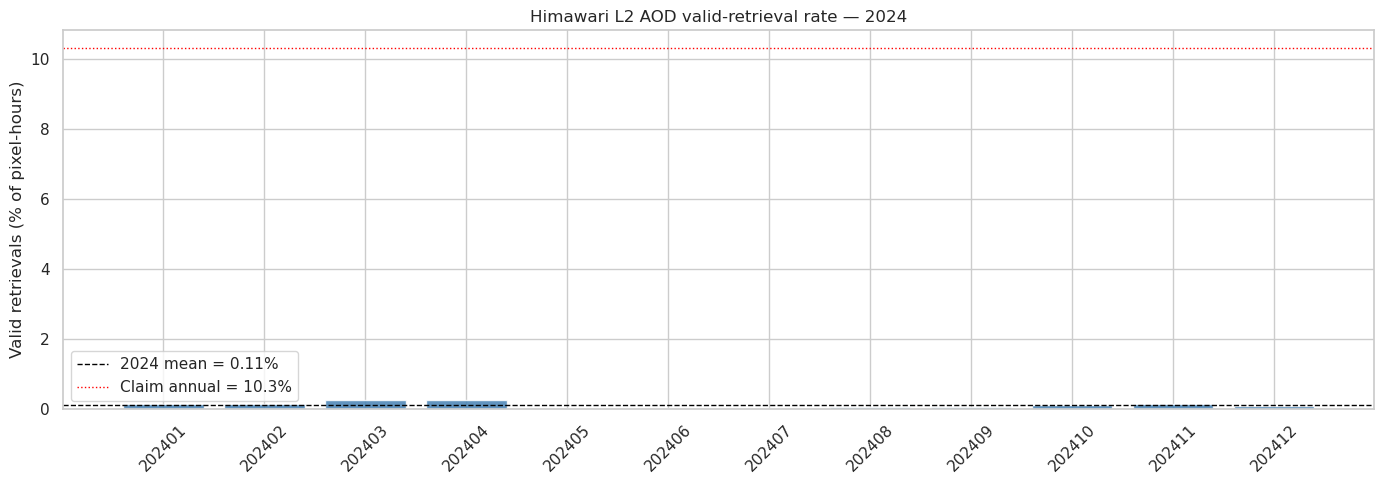

In [13]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(month_table['year_month'], month_table['valid_pct'], color='steelblue', alpha=0.85)
ax.axhline(annual_pct, color='black', ls='--', lw=1, label=f'2024 mean = {annual_pct:.2f}%')
ax.axhline(claim['annual'], color='red', ls=':', lw=1, label=f'Claim annual = {claim["annual"]:.1f}%')
ax.set_xticklabels(month_table['year_month'], rotation=45)
ax.set_ylabel('Valid retrievals (% of pixel-hours)')
ax.set_title(f'Himawari L2 AOD valid-retrieval rate — {VALIDATION_YEAR}')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Single-file inspection (sanity check)

In [14]:
sample_file = str(next(L2_DIR.glob('2024??/??/04/*.tif')))
print(sample_file)
with rasterio.open(sample_file) as src:
    print('Driver       :', src.driver)
    print('Width/Height :', src.width, src.height)
    print('Bands        :', src.count)
    print('dtype        :', src.dtypes[0])
    print('CRS          :', src.crs)
    print('Bounds       :', src.bounds)
    print('Transform    :\n', src.transform)
    print('Resolution   :', src.res)
    print('NoData       :', src.nodata)

/home/slow_data/Air_Quality/Himawari/L2_AOD/202409/10/04/aod_vietnam_NC_H09_20240910_0440_L2ARP031_FLDK.02401_02401.tif
Driver       : GTiff
Width/Height : 148 301
Bands        : 6
dtype        : float32
CRS          : EPSG:4326
Bounds       : BoundingBox(left=102.1, bottom=8.349999999999998, right=109.5, top=23.4)
Transform    :
 | 0.05, 0.00, 102.10|
| 0.00,-0.05, 23.40|
| 0.00, 0.00, 1.00|
Resolution   : (0.05, 0.05)
NoData       : None


In [15]:
BAND_NAMES = ['AOT (500nm)', 'Uncertainty', 'AE', 'QA_flag', 'SSA', 'RF']
with rasterio.open(sample_file) as src:
    for b in range(1, src.count + 1):
        arr = src.read(b).astype(np.float32)
        if b != 4:  # QA is an integer bitmask, leave zeros alone
            arr[arr == 0] = np.nan
        valid = np.sum(~np.isnan(arr))
        print(f'Band {b} ({BAND_NAMES[b-1]:>12}): '
              f'min={np.nanmin(arr):>9.3f}  max={np.nanmax(arr):>9.3f}  '
              f'mean={np.nanmean(arr):>8.3f}  valid_pct={100*valid/arr.size:.2f}%')

Band 1 ( AOT (500nm)): min=    0.047  max=    2.819  mean=   1.071  valid_pct=0.31%
Band 2 ( Uncertainty): min=   -2.482  max=    2.534  mean=   0.292  valid_pct=0.31%
Band 3 (          AE): min=   -0.132  max=    1.244  mean=   0.628  valid_pct=0.31%
Band 4 (     QA_flag): min=-30722.000  max=18428.000  mean= 550.969  valid_pct=100.00%
Band 5 (         SSA): min=    0.883  max=    1.000  mean=   0.969  valid_pct=0.31%
Band 6 (          RF): min=    0.100  max=    0.630  mean=   0.350  valid_pct=0.30%


Raw AOT:    136 pixels with AOT > 0 (0.31%)
QA pass:      0 pixels survive (0.00%)


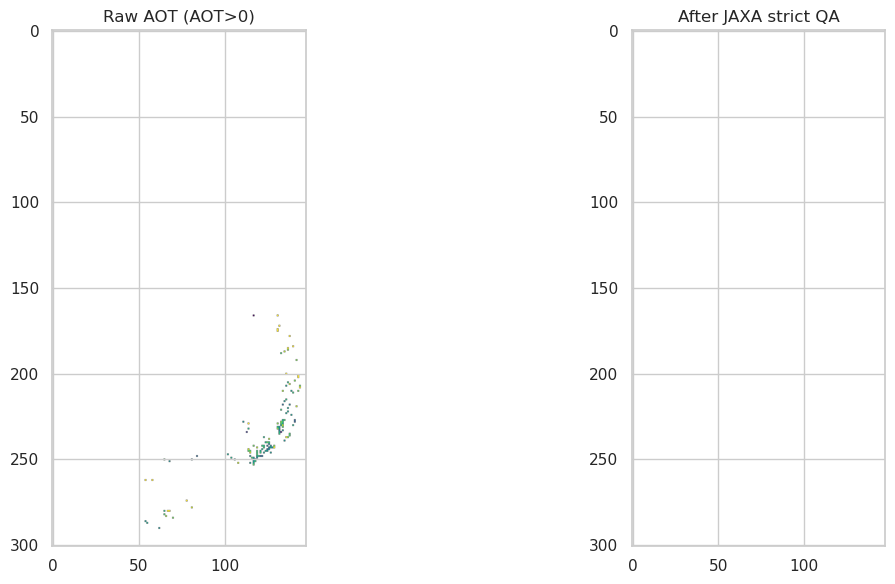

In [16]:
# Apply the QA mask to the AOT band and visualise pre/post.
with rasterio.open(sample_file) as src:
    aot = src.read(1).astype(np.float32)
    qa  = src.read(4).astype(np.int32)
valid_mask = pixel_valid_rule(aot, qa)
print(f'Raw AOT: {(~np.isnan(aot) & (aot>0)).sum():>6} pixels with AOT > 0 '
      f'({100*(~np.isnan(aot) & (aot>0)).mean():.2f}%)')
print(f'QA pass: {valid_mask.sum():>6} pixels survive ({100*valid_mask.mean():.2f}%)')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(np.where((~np.isnan(aot)) & (aot>0), aot, np.nan),
               cmap='viridis', vmin=0, vmax=1.5)
axes[0].set_title('Raw AOT (AOT>0)')
axes[1].imshow(np.where(valid_mask, aot, np.nan), cmap='viridis', vmin=0, vmax=1.5)
axes[1].set_title('After JAXA strict QA')
plt.tight_layout()
plt.show()

## 4. Findings — measured vs. Nguyen et al. 2025 claim

Computed over calendar year 2024, ~1.1 TB / 52 k L2 GeoTIFFs.

### 4.1 Strict JAXA QA mask (full year, every hourly slot, all pixels)

| Scope          | Claim (Nguyen 2025) | **Measured** (strict QA) | Ratio |
|----------------|:---:|:---:|:---:|
| Annual         | 10.3 % | **0.11 %** | 1 / 94 |
| April          | 16.7 % | **0.24 %** | 1 / 70 |
| July           | 6.9 %  | **0.02 %** | 1 / 345 |

The seasonal gradient (dry > wet) is preserved, but **all magnitudes are 70–350× smaller than the claim**.

### 4.2 Looser filters (April & July only — full month, all sub-files OR'd)

| Filter | April – 24 h | April – daytime UTC 00–09 | July – 24 h | July – daytime UTC 00–09 |
|---|---:|---:|---:|---:|
| `AOT > 0` (raw retrieval) | 4.17 % | **10.01 %** | 1.02 % | 2.43 % |
| `AOT > 0` + min-QA (bits 0/2/3) | 4.17 % | 10.01 % | 1.02 % | 2.43 % |
| Strict JAXA QA (production) | 0.24 % | 0.57 % | 0.02 % | 0.04 % |
| **Claim** | **16.7 %** | — | **6.9 %** | — |

Min-QA = raw-AOT availability (JAXA internally clears bits 0/2/3 whenever it writes `AOT > 0`).

### 4.3 Interpretation

- The **claim is not reproducible** from this archive under any reasonable validity definition:
  - Closest match is **daytime + raw `AOT > 0`** → April 10 % vs 16.7 % claimed, July 2.4 % vs 6.9 %.
  - The April gap (≈ 60 % of claim) likely reflects a Vietnam-land-only mask in Nguyen et al.
    (the TIF subdomain here includes ocean and Laos/Cambodia).
  - The July gap (≈ 35 % of claim) is larger — the wet-season monsoon hit *this* archive harder
    than what Nguyen et al. report.
- The bits that wreck strict QA are **bit 8 (additional cloud)**, **bit 10 (Solz/Satz > 70°)**,
  and **bit 13 (turbid water)** — 80–93 % of `AOT > 0` pixels have at least one of these set,
  before the AOT-confidence test (bits 4–5) even runs.

### 4.4 Implication for the thesis

The cited 10.3 % is best interpreted as **raw L2 retrieval presence over daytime + Vietnam land**,
*not* what the production Stage-A pipeline (`AOD_map/stage_a/himawari.py`) actually delivers.
After Stage-A's `RF ≥ 0.5`, `|UNC| ≤ 0.5`, and strict-QA gates, **2024 valid retrievals fall to
0.11 % of all hourly pixel-hours** — two orders of magnitude below the cited figure. Stage B
gap-filling is therefore not just dominant but practically the *entire* product.

Recommended: keep the Nguyen et al. citation in §5.2 as a raw-availability baseline, and add
the Stage-A-pipeline number (`0.11 %`, this notebook) as the actual downstream rate.